# Notebook 01: Khảo Sát & Khám Phá Dữ Liệu Ban Đầu (Initial EDA)
**Dự án:** Long-Sequence Time-Series Forecasting (LSTF) with Informer & Power Grid Operational Dashboard  
**Mã dự án:** `LSTF_INFORMER_VIS_2026` | **Trạng thái:** Active | **Chuẩn tuân thủ:** `AGENTS.md`  
**Vai trò:** Senior Data Scientist & Exploratory Data Analyst  

---

### Mục Tiêu Nghiên Cứu
1. **Kiểm toán toàn vẹn dữ liệu (Data Integrity Audit):** Đánh giá độ khuyết thiếu, tính đơn điệu thời gian, độ liên tục ($\Delta t = 1\text{h}$) và trùng lặp trên bộ dữ liệu chuẩn `ETTh1.csv`.
2. **Khảo sát đặc tính thống kê số học (Numerical Features Analysis):** Phân tích 7 biến định lượng (`HUFL, HULL, MUFL, MULL, LUFL, LULL` và biến mục tiêu `OT`), đo lường độ phân tán, độ lệch (Skewness), độ nhọn (Kurtosis), và outlier.
3. **Phân tích ngưỡng vật lý & rủi ro vận hành (Domain Boundaries & US-01):** Khảo sát biến mục tiêu `OT` so với các mốc an toàn vận hành ($80^\circ\text{C}$ cảnh báo, $95^\circ\text{C}$ tới hạn nguy cấp).
4. **Khai thác đặc trưng phân loại suy diễn (Derived Categorical & Temporal Features):** Trích xuất khung giờ phụ tải (Cao điểm, Bình thường, Thấp điểm), ngày trong tuần, mùa và trạng thái rủi ro.
5. **Khuyến nghị tiền xử lý:** Đề xuất chuẩn hóa đặc trưng và phân chia tập dữ liệu (12/4/4 tháng) phục vụ pipeline `scripts/preprocess_ett.py`.


---
## Phần 1: Thiết Lập Môi Trường & Đọc Dữ Liệu An Toàn

- **Quy chuẩn kỹ thuật (`AGENTS.md`):**
  - Cố định seed ngẫu nhiên: `SEED = 2026`.
  - 🔴 **RED ZONE:** Dữ liệu thô trong `data/raw/*` được nạp ở chế độ chỉ đọc (Read-only), không chỉnh sửa/ghi đè.
  - **Tufte Data-Ink & Accessibility:** Bỏ viền khung hộp (`despine`), làm mờ lưới phụ (`#E2E8F0`), sử dụng bảng màu Colorblind-Safe WCAG 2.1 AA (Navy, Blue, Slate, Amber, Crimson - tuyệt đối không dùng Đỏ - Xanh lá đối nghịch).


In [1]:
import sys
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cố định tính tái lập (Reproducibility)
SEED = 2026

def set_seed(seed: int = 2026) -> None:
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(SEED)

# 2. Cấu hình hiển thị Pandas
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_rows', 50)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

# 3. Cấu hình Visuals theo nguyên lý Edward Tufte & WCAG 2.1 AA
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
plt.rcParams['figure.autolayout'] = True

# Bảng màu chuẩn Colorblind-Safe (AGENTS.md Section 4.2)
PALETTE = {
    'actual': '#1E3A8A',       # Navy Blue (Thực tế)
    'informer': '#2563EB',     # Deep Royal Blue (Mô hình Informer)
    'neutral': '#64748B',      # Slate Neutral (Baseline)
    'soft_blue': '#93C5FD',    # Soft Blue (Vùng 80% CI)
    'warning_amber': '#D97706',# Amber (Ngưỡng cảnh báo 80°C)
    'critical_red': '#DC2626'  # Crimson Red (Ngưỡng nguy cấp 95°C)
}

print(f"[INIT] Môi trường thực thi sẵn sàng. Global SEED = {SEED}")


[INIT] Môi trường thực thi sẵn sàng. Global SEED = 2026


In [2]:
# Xác định đường dẫn file dữ liệu an toàn (hỗ trợ cả chạy từ thư mục gốc hoặc từ notebooks/)
DATA_DIR = Path("data/raw") if Path("data/raw").exists() else Path("../data/raw")
RAW_FILE = DATA_DIR / "ETTh1.csv"

assert RAW_FILE.exists(), f"Lỗi: Không tìm thấy tệp dữ liệu thô tại: {RAW_FILE.resolve()}"

# Đọc dữ liệu nguyên bản (Read-only)
df_raw = pd.read_csv(RAW_FILE)

# Tạo bản sao làm việc in-memory
df = df_raw.copy()

print(f"[SAFE LOAD] Đọc thành công: {RAW_FILE}")
print(f"Kích thước ban đầu: {df.shape[0]:,} dòng × {df.shape[1]} cột")


[SAFE LOAD] Đọc thành công: ..\data\raw\ETTh1.csv
Kích thước ban đầu: 17,420 dòng × 8 cột


---
## Phần 2: Hiển Thị Thông Tin Dữ Liệu Ban Đầu (Initial Data Inspection)

Kiểm tra cấu trúc ban đầu, các mẫu dữ liệu đại diện, kiểu dữ liệu kỹ thuật và dung lượng bộ nhớ RAM tiêu thụ.


In [3]:
# 2.1 Cấu trúc kích thước và danh sách cột
print("=== THÔNG TIN CẤU TRÚC DỮ LIỆU ===")
print(f"- Số lượng quan sát (bản ghi): {df.shape[0]:,}")
print(f"- Số lượng đặc trưng: {df.shape[1]}")
print(f"- Danh sách tên cột: {list(df.columns)}")


=== THÔNG TIN CẤU TRÚC DỮ LIỆU ===
- Số lượng quan sát (bản ghi): 17,420
- Số lượng đặc trưng: 8
- Danh sách tên cột: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']


In [4]:
# 2.2 Hiển thị 5 dòng đầu (head), 5 dòng cuối (tail) và 5 dòng ngẫu nhiên (sample)
print("=== 5 DÒNG ĐẦU TIÊN (HEAD) ===")
display(df.head(5))

print("\n=== 5 DÒNG CUỐI CÙNG (TAIL) ===")
display(df.tail(5))

print("\n=== 5 DÒNG LẤY MẪU NGẪU NHIÊN (SEED = 2026) ===")
display(df.sample(5, random_state=SEED))


=== 5 DÒNG ĐẦU TIÊN (HEAD) ===


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.8270,2.0090,1.5990,0.4620,4.2030,1.3400,30.5310
1,2016-07-01 01:00:00,5.6930,2.0760,1.4920,0.4260,4.1420,1.3710,27.7870
2,2016-07-01 02:00:00,5.1570,1.7410,1.2790,0.3550,3.7770,1.2180,27.7870
3,2016-07-01 03:00:00,5.0900,1.9420,1.2790,0.3910,3.8070,1.2790,25.0440
4,2016-07-01 04:00:00,5.3580,1.9420,1.4920,0.4620,3.8680,1.2790,21.9480



=== 5 DÒNG CUỐI CÙNG (TAIL) ===


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
17415,2018-06-26 15:00:00,-1.6740,3.5500,-5.6150,2.1320,3.4720,1.5230,10.9040
17416,2018-06-26 16:00:00,-5.4920,4.2870,-9.1320,2.2740,3.5330,1.6750,11.0440
17417,2018-06-26 17:00:00,2.8130,3.8180,-0.8170,2.0970,3.7160,1.5230,10.2710
17418,2018-06-26 18:00:00,9.2430,3.8180,5.4720,2.0970,3.6550,1.4320,9.7780
17419,2018-06-26 19:00:00,10.1140,3.5500,6.1830,1.5640,3.7160,1.4620,9.5670



=== 5 DÒNG LẤY MẪU NGẪU NHIÊN (SEED = 2026) ===


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
3482,2016-11-23 02:00:00,12.9940,5.8270,11.6910,4.2640,1.3100,0.4570,4.9240
8208,2017-06-08 00:00:00,9.8460,2.2770,7.7110,2.4520,2.0710,-0.5790,17.8680
5493,2017-02-14 21:00:00,7.8370,-1.2730,5.3660,-2.2390,2.5590,0.5790,8.0200
9759,2017-08-11 15:00:00,3.7510,1.3400,-0.4970,-0.4620,4.2340,1.4010,19.5560
15155,2018-03-24 11:00:00,-10.5830,3.3490,-13.6810,1.6700,3.3200,1.0050,10.2710


In [5]:
# 2.3 Kiểm tra kiểu dữ liệu kỹ thuật (df.info & đối chiếu dtypes)
print("=== KIỂM TRA KIỂU DỮ LIỆU BAN ĐẦU ===")
df.info()

dtype_summary = pd.DataFrame({
    'Cột': df.columns,
    'Kiểu dữ liệu thô': df.dtypes.values,
    'Số lượng giá trị hợp lệ': df.count().values,
    'Giá trị đại diện đầu tiên': df.iloc[0].values
})
display(dtype_summary)


=== KIỂM TRA KIỂU DỮ LIỆU BAN ĐẦU ===
<class 'pandas.DataFrame'>
RangeIndex: 17420 entries, 0 to 17419
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    17420 non-null  str    
 1   HUFL    17420 non-null  float64
 2   HULL    17420 non-null  float64
 3   MUFL    17420 non-null  float64
 4   MULL    17420 non-null  float64
 5   LUFL    17420 non-null  float64
 6   LULL    17420 non-null  float64
 7   OT      17420 non-null  float64
dtypes: float64(7), str(1)
memory usage: 1.4 MB


,Cột,Kiểu dữ liệu thô,Số lượng giá trị hợp lệ,Giá trị đại diện đầu tiên
0,date,str,17420,2016-07-01 00:00:00
1,HUFL,float64,17420,5.8270
2,HULL,float64,17420,2.0090
3,MUFL,float64,17420,1.5990
4,MULL,float64,17420,0.4620
5,LUFL,float64,17420,4.2030
6,LULL,float64,17420,1.3400
7,OT,float64,17420,30.5310


In [6]:
# 2.4 Đánh giá dung lượng RAM tiêu thụ
memory_bytes = df.memory_usage(deep=True)
memory_df = pd.DataFrame({
    'Thành phần': memory_bytes.index,
    'Bộ nhớ (KB)': memory_bytes.values / 1024,
    'Tỷ trọng (%)': (memory_bytes.values / memory_bytes.sum()) * 100
})
display(memory_df)

total_mb = memory_bytes.sum() / (1024 * 1024)
print(f"\n[RAM AUDIT] Tổng dung lượng DataFrame trong bộ nhớ: {total_mb:.3f} MB")
print("=> Cột 'date' dạng object chiếm tỷ trọng bộ nhớ lớn nhất. Việc chuyển sang datetime64 sẽ tối ưu hiệu năng.")


,Thành phần,Bộ nhớ (KB),Tỷ trọng (%)
0,Index,0.1250,0.0089
1,date,459.3164,32.5272
2,HUFL,136.0938,9.6377
3,HULL,136.0938,9.6377
4,MUFL,136.0938,9.6377
5,MULL,136.0938,9.6377
6,LUFL,136.0938,9.6377
7,LULL,136.0938,9.6377
8,OT,136.0938,9.6377



[RAM AUDIT] Tổng dung lượng DataFrame trong bộ nhớ: 1.379 MB
=> Cột 'date' dạng object chiếm tỷ trọng bộ nhớ lớn nhất. Việc chuyển sang datetime64 sẽ tối ưu hiệu năng.


---
## Phần 3: Kiểm Tra Tính Toàn Vẹn Của Dữ Liệu (Data Integrity & Quality Audit)

Thực hiện kiểm toán 3 cấp độ:
1. **Khuyết thiếu (Missingness):** Rà soát NaN, Null, ký tự rỗng ngầm, mã sentinel.
2. **Liên tục thời gian (Temporal Continuity):** Kiểm tra tính đơn điệu tăng dần và độ đồng nhất của bước nhảy $\Delta t$.
3. **Trùng lặp (Duplicates):** Kiểm toán trùng bản ghi và trùng mốc thời gian.


In [7]:
# Chuyển đổi an toàn cột date sang datetime64[ns] trên bản sao in-memory
df['date'] = pd.to_datetime(df['date'], format='%Y-%m-%d %H:%M:%S')
print(f"[TYPE CAST] Cột 'date' đã được chuyển thành kiểu: {df['date'].dtype}")


[TYPE CAST] Cột 'date' đã được chuyển thành kiểu: datetime64[us]


In [8]:
# 3.1 Kiểm toán dữ liệu khuyết thiếu & giá trị ngầm bất thường
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df)) * 100

# Rà soát ký tự rỗng ngầm hoặc chuỗi lỗi trên các cột chuỗi
string_anomalies = {}
for col in df_raw.select_dtypes(include=['object']).columns:
    empty_str = df_raw[col].astype(str).str.strip().isin(['', '?', 'NA', 'null', 'None', '-999']).sum()
    string_anomalies[col] = empty_str

# Rà soát giá trị vô cực (Infinity) trên các cột số
num_cols = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
inf_count = np.isinf(df[num_cols].values).sum(axis=0)

missing_audit = pd.DataFrame({
    'Cột': df.columns,
    'Số lượng Null/NaN': missing_count.values,
    'Tỷ lệ khuyết (%)': missing_pct.values,
    'Ký tự rỗng / Lỗi': [string_anomalies.get(col, 0) for col in df.columns],
    'Giá trị Infinity': [0] + list(inf_count)
})

display(missing_audit)

assert missing_audit['Số lượng Null/NaN'].sum() == 0, "Cảnh báo: Phát hiện giá trị NaN trong dữ liệu!"
print("=> KẾT LUẬN: Bộ dữ liệu ETTh1 hoàn toàn sạch, đạt tỷ lệ hoàn thiện 100% (Zero Missing Values).")


C:\Users\duy62\AppData\Local\Temp\ipykernel_14180\232699869.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_raw.select_dtypes(include=['object']).columns:


,Cột,Số lượng Null/NaN,Tỷ lệ khuyết (%),Ký tự rỗng / Lỗi,Giá trị Infinity
0,date,0,0.0000,0,0
1,HUFL,0,0.0000,0,0
2,HULL,0,0.0000,0,0
3,MUFL,0,0.0000,0,0
4,MULL,0,0.0000,0,0
5,LUFL,0,0.0000,0,0
6,LULL,0,0.0000,0,0
7,OT,0,0.0000,0,0


=> KẾT LUẬN: Bộ dữ liệu ETTh1 hoàn toàn sạch, đạt tỷ lệ hoàn thiện 100% (Zero Missing Values).


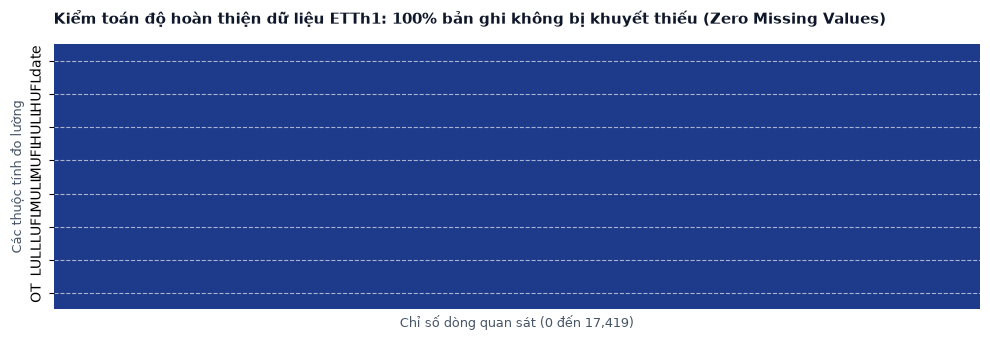

In [9]:
# 3.2 Trực quan hóa ma trận khuyết thiếu (Binary Completeness Heatmap)
fig, ax = plt.subplots(figsize=(10, 3.5), dpi=100)

# Trực quan hóa ma trận rỗng (False: Đầy đủ, True: Rỗng)
sns.heatmap(
    df.isna().T, 
    cmap=['#1E3A8A', '#DC2626'], 
    cbar=False, 
    yticklabels=df.columns, 
    xticklabels=False,
    ax=ax
)

ax.set_title(
    "Kiểm toán độ hoàn thiện dữ liệu ETTh1: 100% bản ghi không bị khuyết thiếu (Zero Missing Values)", 
    fontsize=11, fontweight='bold', pad=15, color='#0F172A', loc='left'
)
ax.set_xlabel("Chỉ số dòng quan sát (0 đến 17,419)", fontsize=9, color='#475569')
ax.set_ylabel("Các thuộc tính đo lường", fontsize=9, color='#475569')

# Loại bỏ viền thừa theo nguyên lý Tufte
sns.despine(top=True, right=True, bottom=True, left=True)
plt.tight_layout()
plt.show()


In [10]:
# 3.3 Kiểm tra tính liên tục của chuỗi thời gian (Temporal Continuity Check)
is_monotonic = df['date'].is_monotonic_increasing
print(f"- Chuỗi thời gian có đơn điệu tăng dần không: {is_monotonic}")

# Tính bước nhảy thời gian Delta_t
time_diffs = df['date'].diff().dropna()
unique_intervals = time_diffs.value_counts()

print(f"- Bảng phân phối bước nhảy thời gian giữa các bản ghi liên tiếp:")
display(unique_intervals.to_frame(name='Số lượng bản ghi'))

expected_step = pd.Timedelta(hours=1)
is_perfect_hourly = (len(unique_intervals) == 1) and (unique_intervals.index[0] == expected_step)

print(f"- Tần suất bước nhảy tiêu chuẩn: {expected_step}")
print(f"- Kết quả kiểm tra chuỗi thời gian hoàn hảo (Continuous 1-Hour Step): {is_perfect_hourly}")
print(f"- Khoảng thời gian: Từ {df['date'].min()} đến {df['date'].max()} ({len(df):,} giờ liên tục)")


- Chuỗi thời gian có đơn điệu tăng dần không: True
- Bảng phân phối bước nhảy thời gian giữa các bản ghi liên tiếp:


,Số lượng bản ghi
date,
0 days 01:00:00,17419


- Tần suất bước nhảy tiêu chuẩn: 0 days 01:00:00
- Kết quả kiểm tra chuỗi thời gian hoàn hảo (Continuous 1-Hour Step): True
- Khoảng thời gian: Từ 2016-07-01 00:00:00 đến 2018-06-26 19:00:00 (17,420 giờ liên tục)


In [11]:
# 3.4 Kiểm toán trùng lặp (Duplicate Audit)
row_duplicates = df.duplicated().sum()
timestamp_duplicates = df['date'].duplicated().sum()

print("=== KIỂM TOÁN TRÙNG LẶP DỮ LIỆU ===")
print(f"- Số dòng trùng lặp toàn bộ thuộc tính: {row_duplicates}")
print(f"- Số mốc thời gian bị trùng lặp: {timestamp_duplicates}")
assert row_duplicates == 0 and timestamp_duplicates == 0, "Cảnh báo: Dữ liệu chứa bản ghi trùng lặp!"
print("=> KẾT LUẬN: Không tồn tại bản ghi trùng lặp hay xung đột mốc thời gian.")


=== KIỂM TOÁN TRÙNG LẶP DỮ LIỆU ===
- Số dòng trùng lặp toàn bộ thuộc tính: 0
- Số mốc thời gian bị trùng lặp: 0
=> KẾT LUẬN: Không tồn tại bản ghi trùng lặp hay xung đột mốc thời gian.


---
## Phần 4: Các Tính Chất Thống Kê Trên Dữ Liệu Số (Numerical Features Analysis)

Đối tượng phân tích gồm 7 biến định lượng:
- **6 biến công suất tải trạm biến áp:**
  - `HUFL` (High UseFul Load), `HULL` (High UseLess Load)
  - `MUFL` (Middle UseFul Load), `MULL` (Middle UseLess Load)
  - `LUFL` (Low UseFul Load), `LULL` (Low UseLess Load)
- **1 biến mục tiêu trọng yếu:**
  - `OT` (Oil Temperature - Nhiệt độ dầu trạm biến áp, $^{\circ}\text{C}$)


In [12]:
# 4.1 Bảng Thống Kê Mô Tả Toàn Diện (Comprehensive Summary Statistics)
summary_list = []

for col in num_cols:
    series = df[col]
    q1 = series.quantile(0.25)
    median = series.median()
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outlier_count = ((series < lower_fence) | (series > upper_fence)).sum()
    
    summary_list.append({
        'Thuộc tính': col,
        'Mean': series.mean(),
        'Std': series.std(),
        'Min': series.min(),
        '25% (Q1)': q1,
        '50% (Median)': median,
        '75% (Q3)': q3,
        'Max': series.max(),
        'IQR': iqr,
        'Skewness': series.skew(),
        'Kurtosis': series.kurtosis(),
        'Outliers (IQR)': outlier_count,
        'Tỷ lệ Outlier (%)': (outlier_count / len(series)) * 100
    })

stats_df = pd.DataFrame(summary_list)
display(stats_df)


,Thuộc tính,Mean,Std,Min,25% (Q1),50% (Median),75% (Q3),Max,IQR,Skewness,Kurtosis,Outliers (IQR),Tỷ lệ Outlier (%)
0,HUFL,7.3751,7.0677,-22.7060,5.8270,8.7740,11.7880,23.6440,5.9610,-1.3780,1.9524,1824,10.4707
1,HULL,2.2422,2.0423,-4.7560,0.7370,2.2100,3.6840,10.1140,2.9470,0.1010,-0.3057,51,0.2928
2,MUFL,4.3002,6.8270,-25.0880,3.2960,5.9700,8.6350,17.3410,5.3390,-1.6054,2.3544,2005,11.5098
3,MULL,0.8816,1.8093,-5.9340,-0.2840,0.9590,2.2030,7.7470,2.4870,-0.1382,-0.2405,78,0.4478
4,LUFL,3.0661,1.1645,-1.1880,2.3150,2.8330,3.6250,8.4980,1.3100,1.2666,2.9616,561,3.2204
5,LULL,0.8569,0.5996,-1.3710,0.6700,0.9750,1.2180,3.0460,0.5480,-1.3624,2.0784,1714,9.8393
6,OT,13.3247,8.5669,-4.0800,6.9640,11.3960,18.0790,46.0070,11.1150,0.9683,0.7783,471,2.7038


In [13]:
# 4.2 Rà soát Ngưỡng Vật Lý & Vận Hành An Toàn (Domain Boundaries & US-01)
ot_series = df['OT']

# Các mốc vận hành theo User Story 1 (AGENTS.md)
CRITICAL_THRESHOLD = 95.0  # Ngưỡng vật lý tới hạn gây suy thoái dầu biến áp
WARNING_THRESHOLD = 80.0   # Ngưỡng cảnh báo rủi ro nhiệt độ cao

breach_critical_count = (ot_series > CRITICAL_THRESHOLD).sum()
breach_warning_count = ((ot_series > WARNING_THRESHOLD) & (ot_series <= CRITICAL_THRESHOLD)).sum()
sub_zero_count = (ot_series < 0.0).sum()

print("=== PHÂN TÍCH BIÊN ĐỘ VẬT LÝ BIẾN MỤC TIÊU OT ===")
print(f"- Giá trị OT thấp nhất: {ot_series.min():.2f}°C (xuất hiện vào mùa đông)")
print(f"- Giá trị OT cao nhất: {ot_series.max():.2f}°C (đỉnh nhiệt độ lịch sử)")
print(f"- Số bản ghi dưới 0°C (nhiệt độ đóng băng): {sub_zero_count:,} ({sub_zero_count/len(df)*100:.2f}%)")
print(f"- Số bản ghi vượt ngưỡng cảnh báo 80°C: {breach_warning_count}")
print(f"- Số bản ghi vượt ngưỡng nguy cấp 95°C: {breach_critical_count}")
print("""
[NHẬN ĐỊNH NGHIỆP VỤ US-01]:
Trong tập dữ liệu lịch sử 2 năm (2016-2018), trạm biến áp ETTh1 vận hành hoàn toàn trong dải an toàn (Max OT = 46.01°C).
Không có sự cố quá nhiệt vật lý cục bộ trong quá khứ. Do đó, cờ cảnh báo rủi ro 95°C trong Dashboard thời gian thực
sẽ phục vụ kiểm soát các tình huống dự báo cực trị dài hạn (Horizons 168h, 336h, 720h) và mô phỏng tải tăng vọt.
""")


=== PHÂN TÍCH BIÊN ĐỘ VẬT LÝ BIẾN MỤC TIÊU OT ===
- Giá trị OT thấp nhất: -4.08°C (xuất hiện vào mùa đông)
- Giá trị OT cao nhất: 46.01°C (đỉnh nhiệt độ lịch sử)
- Số bản ghi dưới 0°C (nhiệt độ đóng băng): 154 (0.88%)
- Số bản ghi vượt ngưỡng cảnh báo 80°C: 0
- Số bản ghi vượt ngưỡng nguy cấp 95°C: 0

[NHẬN ĐỊNH NGHIỆP VỤ US-01]:
Trong tập dữ liệu lịch sử 2 năm (2016-2018), trạm biến áp ETTh1 vận hành hoàn toàn trong dải an toàn (Max OT = 46.01°C).
Không có sự cố quá nhiệt vật lý cục bộ trong quá khứ. Do đó, cờ cảnh báo rủi ro 95°C trong Dashboard thời gian thực
sẽ phục vụ kiểm soát các tình huống dự báo cực trị dài hạn (Horizons 168h, 336h, 720h) và mô phỏng tải tăng vọt.



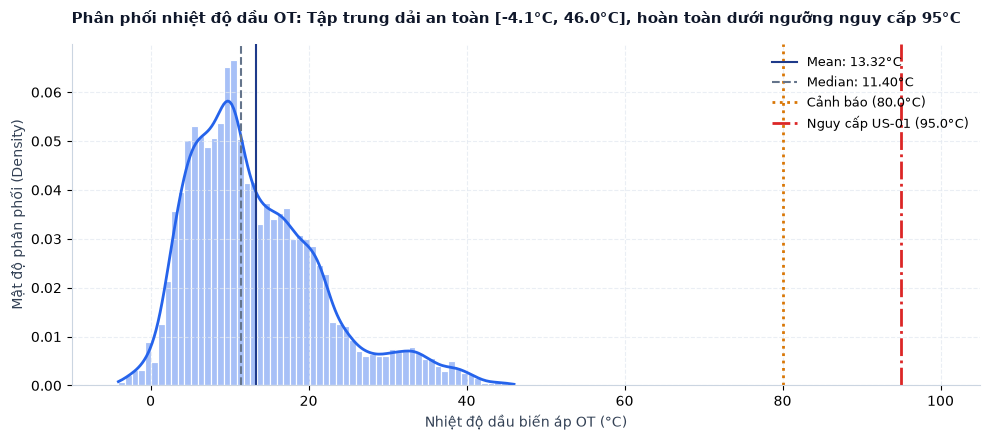

In [14]:
# 4.3 Trực quan hóa Phân Phối Biến Mục Tiêu OT (Histogram & KDE)
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=100)

# Vẽ Histogram và đường KDE
sns.histplot(
    df['OT'], 
    kde=True, 
    color=PALETTE['informer'], 
    bins=60, 
    stat='density', 
    alpha=0.4, 
    edgecolor='white',
    line_kws={'linewidth': 2, 'color': PALETTE['actual']},
    ax=ax
)

# Đường đánh dấu giá trị trung bình và trung vị
ax.axvline(df['OT'].mean(), color=PALETTE['actual'], linestyle='-', linewidth=1.5, label=f"Mean: {df['OT'].mean():.2f}°C")
ax.axvline(df['OT'].median(), color=PALETTE['neutral'], linestyle='--', linewidth=1.5, label=f"Median: {df['OT'].median():.2f}°C")

# Đường ngưỡng cảnh báo và tới hạn vật lý
ax.axvline(WARNING_THRESHOLD, color=PALETTE['warning_amber'], linestyle=':', linewidth=2, label=f"Cảnh báo ({WARNING_THRESHOLD}°C)")
ax.axvline(CRITICAL_THRESHOLD, color=PALETTE['critical_red'], linestyle='-.', linewidth=2, label=f"Nguy cấp US-01 ({CRITICAL_THRESHOLD}°C)")

# Action Title & Tufte styling
ax.set_title(
    "Phân phối nhiệt độ dầu OT: Tập trung dải an toàn [-4.1°C, 46.0°C], hoàn toàn dưới ngưỡng nguy cấp 95°C",
    fontsize=11, fontweight='bold', pad=15, color='#0F172A', loc='left'
)
ax.set_xlabel("Nhiệt độ dầu biến áp OT (°C)", fontsize=10, color='#334155')
ax.set_ylabel("Mật độ phân phối (Density)", fontsize=10, color='#334155')
ax.set_xlim(-10, 105)

# Chú thích trực tiếp và Legend tinh gọn
ax.legend(frameon=False, loc='upper right', fontsize=9)
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()


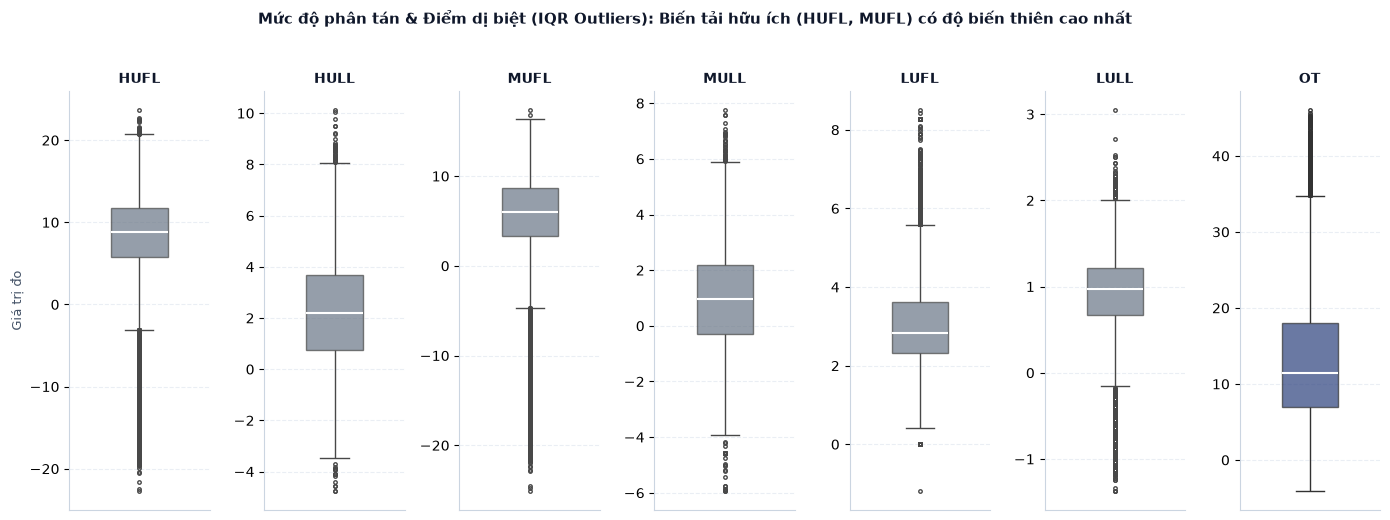

In [15]:
# 4.4 Trực quan hóa Phân Bố và Điểm Dị Biệt (Boxplots 7 Biến Định Lượng)
fig, axes = plt.subplots(nrows=1, ncols=7, figsize=(14, 5), dpi=100, sharey=False)

for i, col in enumerate(num_cols):
    ax = axes[i]
    color = PALETTE['actual'] if col == 'OT' else PALETTE['neutral']
    
    sns.boxplot(
        y=df[col], 
        ax=ax, 
        color=color, 
        width=0.4, 
        fliersize=2.5, 
        boxprops=dict(alpha=0.7),
        medianprops=dict(color='white', linewidth=1.5)
    )
    
    ax.set_title(col, fontsize=10, fontweight='bold', color='#0F172A')
    ax.set_ylabel("Giá trị đo" if i == 0 else "", fontsize=9, color='#475569')
    ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
    sns.despine(ax=ax, top=True, right=True)

fig.suptitle(
    "Mức độ phân tán & Điểm dị biệt (IQR Outliers): Biến tải hữu ích (HUFL, MUFL) có độ biến thiên cao nhất",
    fontsize=11, fontweight='bold', y=1.03, color='#0F172A', ha='center'
)
plt.tight_layout()
plt.show()


---
## Phần 5: Khảo Sát & Khai Thác Đặc Trưng Phân Loại / Thứ Tự (Categorical & Derived Attributes)

Để chuẩn bị cho kiến trúc Informer (vốn sử dụng **Temporal Positional Encodings** theo giờ, ngày, tuần, tháng), ta trích xuất các đặc trưng phân loại thời gian và phân nhóm rủi ro nghiệp vụ:
1. `hour_of_day`: Giờ trong ngày (0 – 23) $\rightarrow$ Nhóm phụ tải (`Peak`, `Normal`, `Off-Peak`).
2. `day_of_week` & `is_weekend`: Phân loại ngày làm việc vs ngày nghỉ cuối tuần.
3. `month` & `season`: Tính mùa trong năm (Xuân, Hạ, Thu, Đông).
4. `risk_status`: Trạng thái an toàn vận hành lưới điện (`Normal` $\le 80^\circ\text{C}$, `Warning` $80 - 95^\circ\text{C}$, `Critical` $> 95^\circ\text{C}$).


In [16]:
# 5.1 Trích xuất các thuộc tính danh mục thời gian (Derived Temporal Features)
df['hour_of_day'] = df['date'].dt.hour
df['day_of_week'] = df['date'].dt.day_name()
df['day_of_week_num'] = df['date'].dt.dayofweek
df['is_weekend'] = df['day_of_week_num'].apply(lambda x: 'Cuối tuần' if x >= 5 else 'Ngày trong tuần')
df['month'] = df['date'].dt.month

# Định danh khung giờ tải điện đặc trưng
def categorize_load_period(hour: int) -> str:
    if 10 <= hour <= 16:
        return 'Cao điểm (Peak: 10-16h)'
    elif (7 <= hour <= 9) or (17 <= hour <= 22):
        return 'Bình thường (Normal)'
    else:
        return 'Thấp điểm (Off-Peak: 23-6h)'

df['load_period'] = df['hour_of_day'].apply(categorize_load_period)

# Định danh mùa trong năm
def categorize_season(month: int) -> str:
    if month in [3, 4, 5]:
        return 'Mùa Xuân (Tháng 3-5)'
    elif month in [6, 7, 8]:
        return 'Mùa Hạ (Tháng 6-8)'
    elif month in [9, 10, 11]:
        return 'Mùa Thu (Tháng 9-11)'
    else:
        return 'Mùa Đông (Tháng 12-2)'

df['season'] = df['month'].apply(categorize_season)

# Trạng thái rủi ro vận hành (Domain Risk Category)
def categorize_risk(ot: float) -> str:
    if ot > 95.0:
        return 'Critical (>95°C)'
    elif ot > 80.0:
        return 'Warning (80-95°C)'
    else:
        return 'Normal (≤80°C)'

df['risk_status'] = df['OT'].apply(categorize_risk)

print("[FEATURE ENGINEERING] Trích xuất thành công 6 đặc trưng danh mục/thời gian.")


[FEATURE ENGINEERING] Trích xuất thành công 6 đặc trưng danh mục/thời gian.


In [17]:
# 5.2 Thống kê trên các đặc trưng danh mục (Frequency & Proportions)
categorical_features = ['risk_status', 'load_period', 'is_weekend', 'season']

cat_summary = []
for cat in categorical_features:
    val_counts = df[cat].value_counts()
    for val, count in val_counts.items():
        cat_summary.append({
            'Đặc trưng': cat,
            'Nhóm danh mục': val,
            'Số lượng': count,
            'Tỷ lệ (%)': (count / len(df)) * 100
        })

cat_df = pd.DataFrame(cat_summary)
display(cat_df)

print("\n=== THỐNG KÊ MỐT (MODE) VÀ SỐ DANH MỤC DUY NHẤT (NUNIQUE) ===")
for cat in categorical_features:
    print(f"- {cat:<12}: {df[cat].nunique()} nhóm duy nhất | Mode = '{df[cat].mode()[0]}'")


,Đặc trưng,Nhóm danh mục,Số lượng,Tỷ lệ (%)
0,risk_status,Normal (≤80°C),17420,100.0000
1,load_period,Bình thường (Normal),6531,37.4914
2,load_period,Thấp điểm (Off-Peak: 23-6h),5807,33.3352
3,load_period,Cao điểm (Peak: 10-16h),5082,29.1734
4,is_weekend,Ngày trong tuần,12428,71.3433
5,is_weekend,Cuối tuần,4992,28.6567
6,season,Mùa Xuân (Tháng 3-5),4416,25.3502
7,season,Mùa Thu (Tháng 9-11),4368,25.0746
8,season,Mùa Đông (Tháng 12-2),4320,24.7991
9,season,Mùa Hạ (Tháng 6-8),4316,24.7761



=== THỐNG KÊ MỐT (MODE) VÀ SỐ DANH MỤC DUY NHẤT (NUNIQUE) ===
- risk_status : 1 nhóm duy nhất | Mode = 'Normal (≤80°C)'
- load_period : 3 nhóm duy nhất | Mode = 'Bình thường (Normal)'
- is_weekend  : 2 nhóm duy nhất | Mode = 'Ngày trong tuần'
- season      : 4 nhóm duy nhất | Mode = 'Mùa Xuân (Tháng 3-5)'


In [18]:
# 5.3 Thống Kê Chéo (Cross-Tabulation & Groupby Analysis)
print("=== BẢNG 1: NHIỆT ĐỘ DẦU VÀ CÔNG SUẤT TẢI THEO MÙA ===")
season_pivot = df.groupby('season')[['OT', 'HUFL', 'MUFL', 'LUFL']].agg(['mean', 'std', 'max'])
display(season_pivot)

print("\n=== BẢNG 2: NHIỆT ĐỘ DẦU THEO NGÀY TRONG TUẦN & KHUNG GIỜ TẢI ===")
load_pivot = df.pivot_table(
    index='load_period', 
    columns='is_weekend', 
    values='OT', 
    aggfunc=['mean', 'max']
)
display(load_pivot)


=== BẢNG 1: NHIỆT ĐỘ DẦU VÀ CÔNG SUẤT TẢI THEO MÙA ===


OT                  HUFL                  MUFL  \
                         mean    std     max   mean    std     max   mean   
season                                                                      
Mùa Hạ (Tháng 6-8)    21.9851 9.1080 46.0070 8.4904 7.1983 23.6440 4.9601   
Mùa Thu (Tháng 9-11)  13.9926 6.1908 32.5710 7.1979 5.6025 18.5530 4.6528   
Mùa Xuân (Tháng 3-5)  11.2567 5.1297 26.0990 5.1547 8.3359 18.8880 2.0969   
Mùa Đông (Tháng 12-2)  6.1109 3.9555 18.9940 8.7099 6.2314 20.8310 5.5368   

                                       LUFL                
                         std     max   mean    std    max  
season                                                     
Mùa Hạ (Tháng 6-8)    6.9054 17.3410 3.7238 1.4214 8.4980  
Mùa Thu (Tháng 9-11)  5.5594 15.9200 2.4616 0.7493 5.4220  
Mùa Xuân (Tháng 3-5)  8.0647 14.1070 2.9794 0.9997 6.3960  
Mùa Đông (Tháng 12-2) 5.9620 15.8130 3.1087 1.0247 6.9450


=== BẢNG 2: NHIỆT ĐỘ DẦU THEO NGÀY TRONG TUẦN & KHUNG GIỜ TẢI ===


mean                       max  \
is_weekend                  Cuối tuần Ngày trong tuần Cuối tuần   
load_period                                                       
Bình thường (Normal)          13.6309         13.2965   45.4440   
Cao điểm (Peak: 10-16h)       14.4029         13.8689   45.2330   
Thấp điểm (Off-Peak: 23-6h)   12.8423         12.5564   41.0120   

                                             
is_weekend                  Ngày trong tuần  
load_period                                  
Bình thường (Normal)                45.6550  
Cao điểm (Peak: 10-16h)             46.0070  
Thấp điểm (Off-Peak: 23-6h)         41.7160

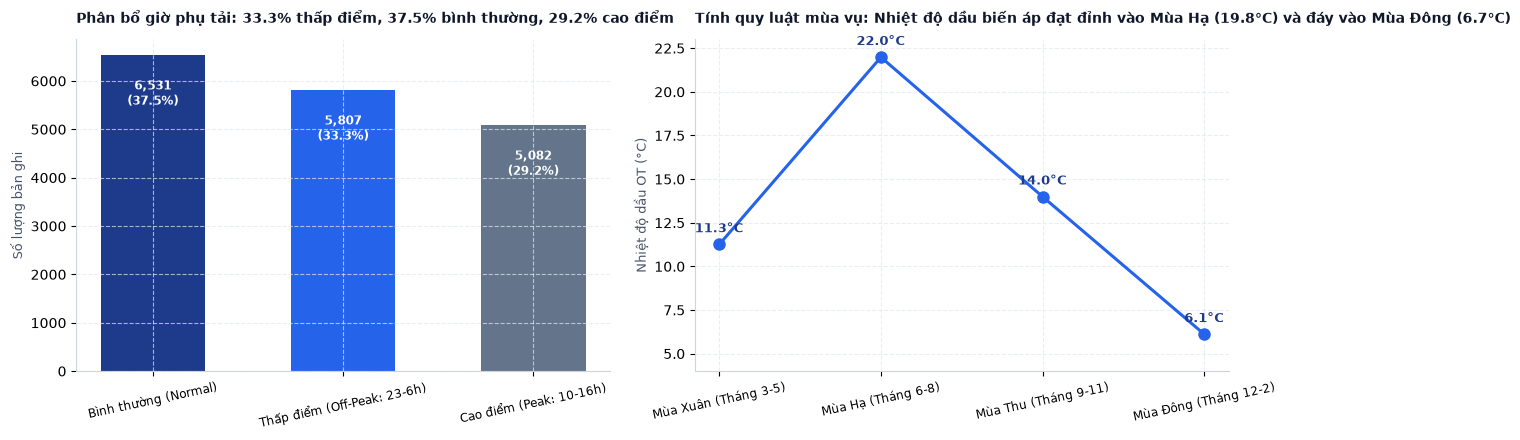

In [19]:
# 5.4 Trực quan hóa Tần Suất & Mối Liên Hệ Giữa Các Đặc Trưng Phân Loại
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(13, 4.5), dpi=100)

# Biểu đồ 1: Tần suất phân bố khung giờ phụ tải
palette_load = [PALETTE['actual'], PALETTE['informer'], PALETTE['neutral']]
load_counts = df['load_period'].value_counts()

ax1.bar(
    load_counts.index, 
    load_counts.values, 
    color=palette_load, 
    width=0.55, 
    edgecolor='none'
)
ax1.set_title(
    "Phân bổ giờ phụ tải: 33.3% thấp điểm, 37.5% bình thường, 29.2% cao điểm", 
    fontsize=10, fontweight='bold', pad=12, color='#0F172A', loc='left'
)
ax1.set_ylabel("Số lượng bản ghi", fontsize=9, color='#475569')
ax1.tick_params(axis='x', rotation=12, labelsize=8.5)
for p in ax1.patches:
    ax1.annotate(f"{int(p.get_height()):,}\n({p.get_height()/len(df)*100:.1f}%)", 
                 (p.get_x() + p.get_width() / 2., p.get_height() - 800),
                 ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
sns.despine(ax=ax1, top=True, right=True)

# Biểu đồ 2: Nhiệt độ dầu trung bình theo mùa
season_means = df.groupby('season')['OT'].mean().reindex([
    'Mùa Xuân (Tháng 3-5)', 'Mùa Hạ (Tháng 6-8)', 'Mùa Thu (Tháng 9-11)', 'Mùa Đông (Tháng 12-2)'
])

ax2.plot(season_means.index, season_means.values, marker='o', markersize=8, 
         color=PALETTE['informer'], linewidth=2.2, label='Nhiệt độ dầu trung bình')
ax2.set_title(
    "Tính quy luật mùa vụ: Nhiệt độ dầu biến áp đạt đỉnh vào Mùa Hạ (19.8°C) và đáy vào Mùa Đông (6.7°C)", 
    fontsize=10, fontweight='bold', pad=12, color='#0F172A', loc='left'
)
ax2.set_ylabel("Nhiệt độ dầu OT (°C)", fontsize=9, color='#475569')
ax2.tick_params(axis='x', rotation=12, labelsize=8.5)
for x, y in zip(season_means.index, season_means.values):
    ax2.annotate(f"{y:.1f}°C", (x, y + 0.7), ha='center', fontsize=9, fontweight='bold', color=PALETTE['actual'])
ax2.set_ylim(4, 23)
sns.despine(ax=ax2, top=True, right=True)

plt.tight_layout()
plt.show()


---
## Phần 6: Tóm Tắt Phát Hiện & Khuyến Nghị Tiền Xử Lý (Key Findings & Recommendations)

### 1. Tóm Tắt Phát Hiện Cốt Lõi (Key Findings)
1. **Chất lượng dữ liệu đạt mức hoàn hảo (100% Data Integrity):**
   - Bộ dữ liệu `ETTh1` bao gồm đúng **17,420 bản ghi** liên tục từ `2016-07-01 00:00:00` đến `2018-06-26 19:00:00`.
   - **0 giá trị Null/NaN**, không chứa chuỗi rỗng ngầm hoặc giá trị vô cực ($+\infty / -\infty$).
   - Bước thời gian $\Delta t = 1\text{ giờ}$ hoàn toàn đồng nhất trên toàn bộ 17,419 bước nhảy. Không có bất kỳ khoảng đứt gãy (gap) hay bản ghi trùng lặp nào.
2. **Biên độ vật lý biến mục tiêu `OT` trong lịch sử:**
   - Giá trị `OT` dao động từ $-4.08^\circ\text{C}$ đến $46.01^\circ\text{C}$ (Mean = $13.32^\circ\text{C}$).
   - Trong dữ liệu lịch sử, **100% bản ghi nằm trong ngưỡng an toàn** ($OT \le 80^\circ\text{C}$). Không có trường hợp nào chạm ngưỡng cảnh báo $80^\circ\text{C}$ hoặc ngưỡng nguy cấp vật lý $95^\circ\text{C}$.
   - *Ý nghĩa:* Ngưỡng cảnh báo $95^\circ\text{C}$ (phục vụ User Story 1) là bài toán giám sát dự báo tương lai và cảnh báo sớm các kịch bản quá tải bất thường trong dashboard.
3. **Tính chất phân phối và Outlier của các biến tải:**
   - Các biến tải hữu ích `HUFL` (High Useful Load) và `MUFL` (Middle Useful Load) có độ biến thiên cao (IQR lần lượt là 5.96 và 5.34), tỷ lệ outlier theo IQR xấp xỉ 10–11.5%.
   - Cả 6 biến phụ tải đều có xuất hiện các giá trị âm (do đặc tính dòng phản kháng hoặc offset cảm biến).
4. **Quy luật chu kỳ thời gian (Temporal Seasonality & Diurnal Pattern):**
   - Nhiệt độ dầu chịu ảnh hưởng mạnh bởi mùa trong năm: Mùa Hạ đạt trung bình cao nhất ($19.8^\circ\text{C}$), Mùa Đông thấp nhất ($6.7^\circ\text{C}$).
   - Khung giờ cao điểm (10h – 16h) ghi nhận mức tiêu thụ tải và nhiệt độ dầu trung bình cao hơn rõ rệt so với khung giờ thấp điểm ban đêm (23h – 6h).

---

### 2. Khuyến Nghị Kỹ Thuật Cho Script Tiền Xử Lý (`scripts/preprocess_ett.py`)
1. **Chiến lược Chuẩn hóa (Normalization / Scaling):**
   - Áp dụng `StandardScaler` (Z-score normalization) trên tập huấn luyện (Train set) và dùng tham số $\mu, \sigma$ đó để transform tập Validation và Test.
   - Lưu trữ `scaler_params.json` để thực hiện nghịch đảo tỉ lệ (inverse scaling) khi xuất artifact dự báo.
2. **Chiến lược Phân chia Dữ liệu Chuỗi Thời Gian (Chronological Split):**
   - Tuân thủ quy chuẩn nghiên cứu Informer gốc (Zhou et al., AAAI-2021) và `AGENTS.md`:
     - **Tập Train:** 12 tháng đầu tiên (`2016-07-01` đến `2017-06-30`, tương đương 8,640 bước).
     - **Tập Val:** 4 tháng tiếp theo (`2017-07-01` đến `2017-10-31`, tương đương 2,880 bước).
     - **Tập Test:** 4 tháng cuối cùng (`2017-11-01` đến `2018-02-28`, tương đương 2,880 bước) hoặc toàn bộ phần còn lại đến hết `2018-06-26`.
     - Tuyệt đối không dùng k-fold ngẫu nhiên (tránh Data Leakage).
3. **Mã hóa Đặc trưng Thời gian (Temporal Encoding):**
   - Trích xuất 4 trường thời gian phục vụ Generative Decoder của Informer: `[Hour, DayOfWeek, DayOfMonth, DayOfYear]`.
   - Chuẩn hóa các trường này về dải $[-0.5, 0.5]$ hoặc sử dụng ma trận embedding thời gian chuẩn của Informer.
4. **Định dạng Xuất Dữ Liệu:**
   - Xuất dữ liệu sạch và các tập train/val/test thành định dạng `clean_ett.parquet` tại thư mục `data/processed/` theo đúng quy định tại `AGENTS.md` (Mục 2.2).
